In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")

display(df.head())


Saving retail_sales_dataset.csv to retail_sales_dataset (1).csv
Dataset loaded successfully!


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [ ]:

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

display(df.describe())


Dataset Shape: (1000, 9)

Column Names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Qu

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [ ]:

df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

print("Date column converted successfully!")
print(df['Date'].dtype)


Date column converted successfully!
datetime64[ns]


In [ ]:

print("Missing values before cleaning:")
print(df.isnull().sum())

# Remove duplicate records
df = df.drop_duplicates()

# Remove rows with missing essential values
df = df.dropna(subset=[
    'Date',
    'Customer ID',
    'Product Category',
    'Total Amount'
])

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nDataset shape after cleaning:", df.shape)


Missing values before cleaning:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Missing values after cleaning:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Dataset shape after cleaning: (1000, 9)


In [ ]:

print("Updated Data Types:")
print(df.dtypes)

print("\nStatistical Summary:")
display(df.describe())



Updated Data Types:
Transaction ID               int64
Date                datetime64[ns]
Customer ID                 object
Gender                      object
Age                          int64
Product Category            object
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object

Statistical Summary:


,Transaction ID,Date,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,2023-07-03 00:25:55.200000256,41.39200,2.514000,179.890000,456.000000
min,1.000000,2023-01-01 00:00:00,18.00000,1.000000,25.000000,25.000000
25%,250.750000,2023-04-08 00:00:00,29.00000,1.000000,30.000000,60.000000
50%,500.500000,2023-06-29 12:00:00,42.00000,3.000000,50.000000,135.000000
75%,750.250000,2023-10-04 00:00:00,53.00000,4.000000,300.000000,900.000000
max,1000.000000,2024-01-01 00:00:00,64.00000,4.000000,500.000000,2000.000000
std,288.819436,NaN,13.68143,1.132734,189.681356,559.997632


In [ ]:

numerical_columns = [
    'Age',
    'Quantity',
    'Price per Unit',
    'Total Amount'
]

statistics = pd.DataFrame({
    'Mean': df[numerical_columns].mean(),
    'Median': df[numerical_columns].median(),
    'Mode': df[numerical_columns].mode().iloc[0],
    'Standard Deviation': df[numerical_columns].std()
})

display(statistics)



,Mean,Median,Mode,Standard Deviation
Age,41.392,42.0,43.0,13.681430
Quantity,2.514,3.0,4.0,1.132734
Price per Unit,179.890,50.0,50.0,189.681356
Total Amount,456.000,135.0,50.0,559.997632


In [ ]:

print("Gender Distribution:")
print(df['Gender'].value_counts())

print("\nProduct Category Distribution:")
print(df['Product Category'].value_counts())

# Create age groups
df['Age Group'] = pd.cut(
    df['Age'],
    bins=[0, 20, 30, 40, 50, 60, 100],
    labels=['Below 20', '21-30', '31-40',
            '41-50', '51-60', 'Above 60']
)

print("\nAge Group Distribution:")
print(df['Age Group'].value_counts().sort_index())


Gender Distribution:
Gender
Female    510
Male      490
Name: count, dtype: int64

Product Category Distribution:
Product Category
Clothing       351
Electronics    342
Beauty         307
Name: count, dtype: int64

Age Group Distribution:
Age Group
Below 20     63
21-30       210
31-40       193
41-50       221
51-60       220
Above 60     93
Name: count, dtype: int64


In [ ]:

print("Gender Distribution:")
print(df['Gender'].value_counts())

print("\nProduct Category Distribution:")
print(df['Product Category'].value_counts())

# Create age groups
df['Age Group'] = pd.cut(
    df['Age'],
    bins=[0, 20, 30, 40, 50, 60, 100],
    labels=['Below 20', '21-30', '31-40',
            '41-50', '51-60', 'Above 60']
)

print("\nAge Group Distribution:")
print(df['Age Group'].value_counts().sort_index())


Gender Distribution:
Gender
Female    510
Male      490
Name: count, dtype: int64

Product Category Distribution:
Product Category
Clothing       351
Electronics    342
Beauty         307
Name: count, dtype: int64

Age Group Distribution:
Age Group
Below 20     63
21-30       210
31-40       193
41-50       221
51-60       220
Above 60     93
Name: count, dtype: int64


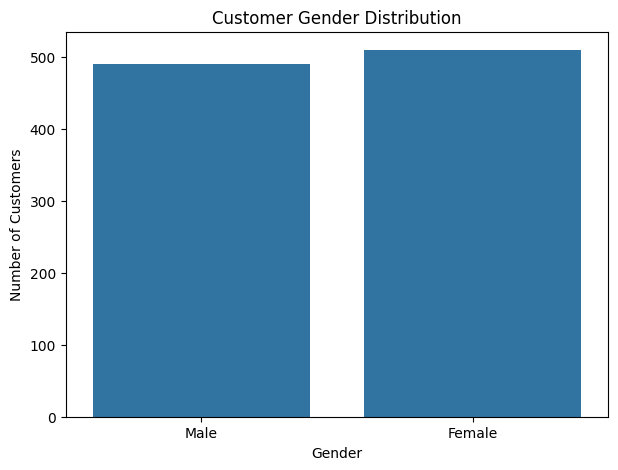

In [ ]:

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Gender'
)

plt.title('Customer Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')
plt.show()


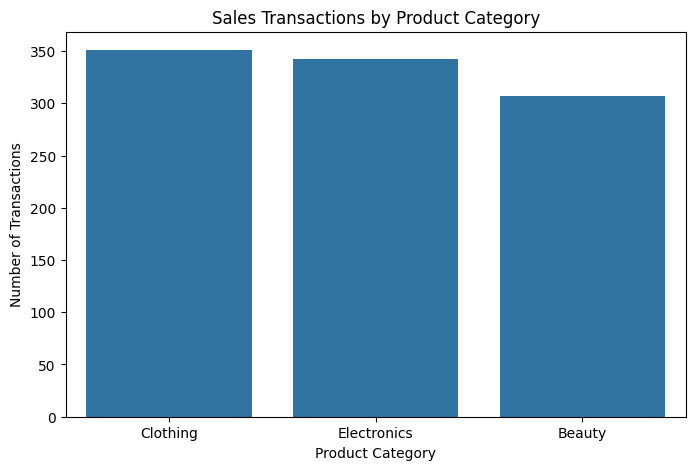

In [ ]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Product Category',
    order=df['Product Category'].value_counts().index
)

plt.title('Sales Transactions by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Number of Transactions')
plt.show()


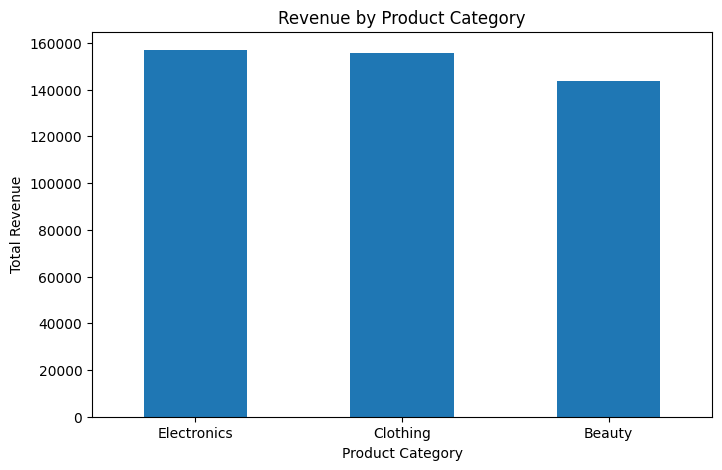

,Total Amount
Product Category,
Electronics,156905
Clothing,155580
Beauty,143515


In [ ]:

category_sales = df.groupby(
    'Product Category'
)['Total Amount'].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))

category_sales.plot(
    kind='bar',
    title='Revenue by Product Category',
    xlabel='Product Category',
    ylabel='Total Revenue'
)

plt.xticks(rotation=0)
plt.show()

display(category_sales)


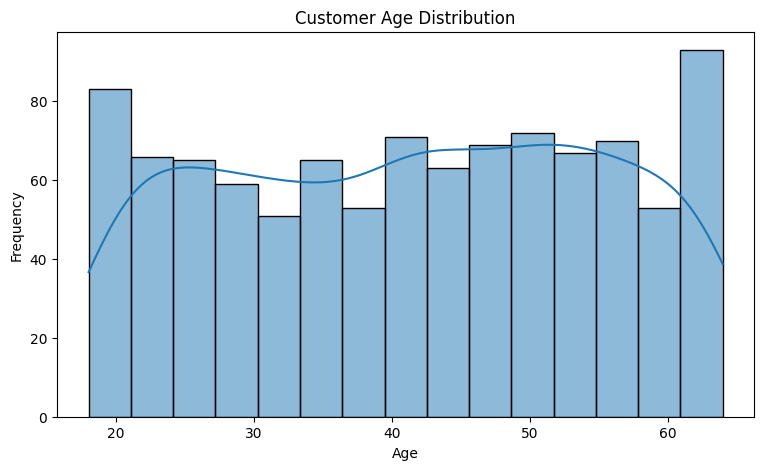

In [ ]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='Age',
    bins=15,
    kde=True
)

plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()


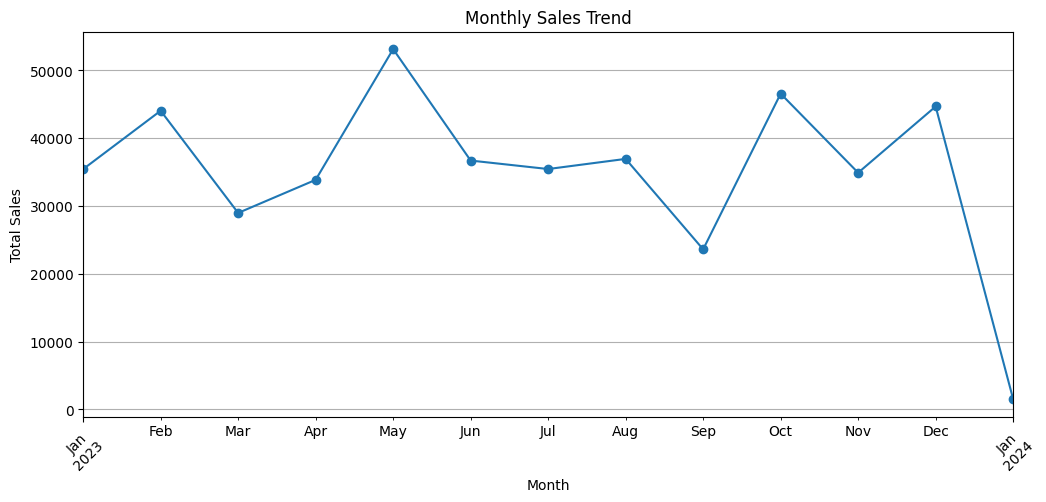

In [ ]:

df['Month'] = df['Date'].dt.to_period('M')

monthly_sales = df.groupby(
    'Month'
)['Total Amount'].sum()

plt.figure(figsize=(12, 5))

monthly_sales.plot(marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()


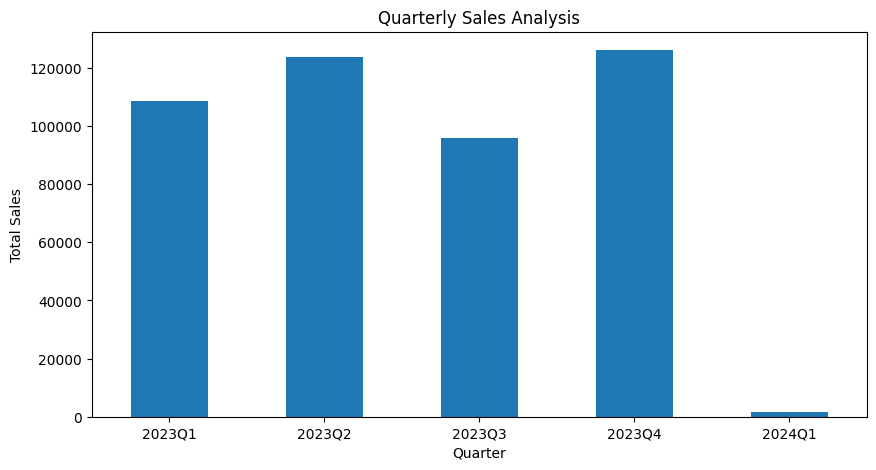

,Total Amount
Quarter,
2023Q1,108500
2023Q2,123735
2023Q3,96045
2023Q4,126190
2024Q1,1530


In [ ]:

df['Quarter'] = df['Date'].dt.to_period('Q')

quarterly_sales = df.groupby(
    'Quarter'
)['Total Amount'].sum()

plt.figure(figsize=(10, 5))

quarterly_sales.plot(
    kind='bar',
    title='Quarterly Sales Analysis'
)

plt.xlabel('Quarter')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.show()

display(quarterly_sales)


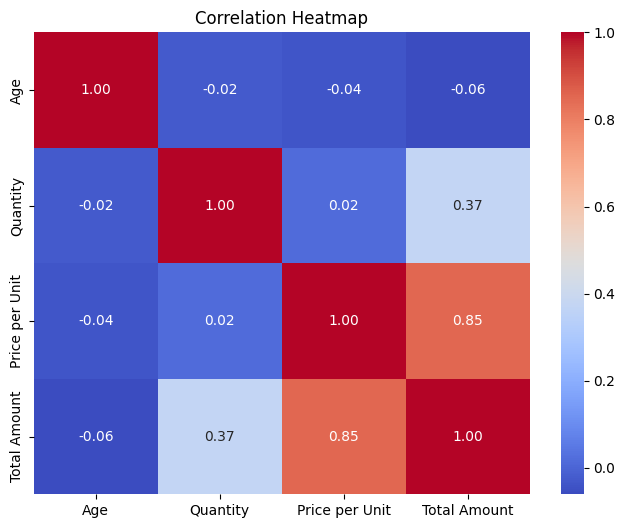

In [ ]:

plt.figure(figsize=(8, 6))

correlation = df[
    ['Age', 'Quantity', 'Price per Unit', 'Total Amount']
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()


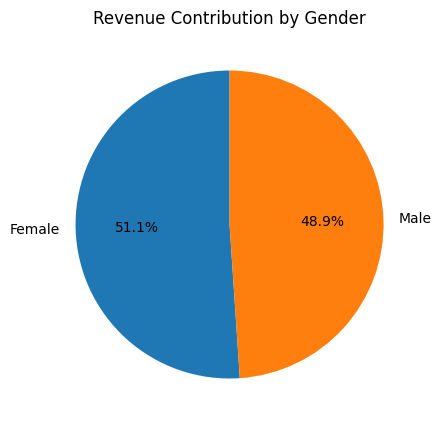

In [ ]:

gender_revenue = df.groupby(
    'Gender'
)['Total Amount'].sum()

plt.figure(figsize=(7, 5))

gender_revenue.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Revenue Contribution by Gender')
plt.ylabel('')
plt.show()


In [ ]:

top_categories = df.groupby(
    'Product Category'
)['Quantity'].sum().sort_values(ascending=False)

print("Top-selling product categories:")
display(top_categories)


Top-selling product categories:


,Quantity
Product Category,
Clothing,894
Electronics,849
Beauty,771
